# Kitaev's Toric Code — Numerical simulation

**CY Tech · DATA SCIENCE GROUP · June 2026**  
*Supervisor: Garrigue*  
*Revised in October 2026: text aligned with the results, see `ERRATA.md`. The simulation functions are unchanged.*

This notebook simulates the error dynamics of the toric code through a **classical stochastic Pauli channel**.  
We work directly on the **syndrome** (the grid of eigenvalues $B_p \in \{-1,+1\}$), which is exactly what a decoder sees in practice.

> **Scope of the simulation.** The model applies **no correction** (no decoder). The syndrome therefore evolves freely under noise and its anyon density converges to $1/2$, whatever the value of $p$. The threshold $p_{\text{threshold}} \approx 0.103$ quoted below is a result from the literature (Dennis et al., 2002), **not** a quantity measured here: measuring it would require simulating the full *code capacity model* with an MWPM decoder (see "Summary").

### Structure
1. Model and basic functions
2. Simulation and visualization — low noise ($p = 0.01$)
3. Anyon density vs $p$
4. Comparison of three values of $p$

---

*Version française*

# Code Torique de Kitaev — Simulation numérique

**CY Tech · DATA SCIENCE GROUP · Juin 2026**  
*Superviseur : Garrigue*  
*Version révisée en octobre 2026 : textes alignés sur les résultats, voir `ERRATA.md`. Les fonctions de simulation sont inchangées.*

Ce notebook simule la dynamique d'erreurs du code torique via un **canal de Pauli stochastique classique**.  
On travaille directement sur le **syndrome** (grille des valeurs propres $B_p \in \{-1,+1\}$), ce qui est exactement ce que voit un décodeur en pratique.

> **Portée de la simulation.** Le modèle n'applique **aucune correction** (pas de décodeur). Le syndrome évolue donc librement sous le bruit et sa densité d'anyons converge vers $1/2$, quelle que soit la valeur de $p$. Le seuil $p_{\text{seuil}} \approx 0.103$ cité plus bas est un résultat de la littérature (Dennis et al., 2002), **pas** une quantité mesurée ici : le mesurer demanderait de simuler le *code capacity model* avec un décodeur MWPM (voir « Bilan »).

### Structure
1. Modèle et fonctions de base  
2. Simulation et visualisation — faible bruit ($p = 0.01$)  
3. Densité d'anyons vs $p$  
4. Comparaison de trois valeurs de $p$

## 1. Model and basic functions — *Modèle et fonctions de base*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.animation import FuncAnimation
from tqdm import tqdm

np.random.seed(42)  # résultats reproductibles

plt.rcParams.update({
    'figure.dpi': 120,
    'axes.facecolor': '#0d0d0d',
    'figure.facecolor': '#1a1a1a',
    'text.color': 'white',
    'axes.labelcolor': 'white',
    'xtick.color': 'white',
    'ytick.color': 'white',
    'axes.titlecolor': 'white',
    'axes.edgecolor': '#444',
    'grid.color': '#333',
})

### Structure of the $L \times L$ toric lattice

Qubits sit on the **edges** of the lattice. We distinguish:
- **horizontal** edges $e = (i,j)_h$ — index $i \cdot L + j$
- **vertical** edges $e = (i,j)_v$ — index $L^2 + i \cdot L + j$

Each edge is adjacent to exactly **2 plaquettes** (periodic boundary conditions = torus).

---

*Version française*

### Structure du réseau torique $L \times L$

Les qubits sont sur les **arêtes** du réseau. On distingue :
- arêtes **horizontales** $e = (i,j)_h$ — indice $i \cdot L + j$  
- arêtes **verticales** $e = (i,j)_v$ — indice $L^2 + i \cdot L + j$

Chaque arête est adjacente à exactement **2 plaquettes** (conditions périodiques = tore).

In [2]:
def edge_h(i0, j0, L):
    """Arête horizontale en (i0, j0) mod L."""
    return (i0 % L) * L + (j0 % L), 'h'

def edge_v(i0, j0, L):
    """Arête verticale en (i0, j0) mod L."""
    return edge_h(i0, j0, L)[0] + L**2, 'v'

def adjacent_plaquettes(e, L):
    """Renvoie les 2 plaquettes adjacentes à l'arête e (indices mod L)."""
    i, j = e[0] // L, e[0] % L
    if e[1] == 'h':
        return [(i - 1) % L, j], [i % L, j]
    else:
        return [i % L, (j - 1) % L], [i % L, j % L]

# Test de cohérence : chaque arête doit avoir exactement 2 plaquettes adjacentes
L_test = 5
e = edge_h(2, 3, L_test)
p1, p2 = adjacent_plaquettes(e, L_test)
print(f"Edge {e} → plaquettes {p1} and {p2}  ✓")


Edge (13, 'h') → plaquettes [1, 3] and [2, 3]  ✓


### Stochastic Pauli channel (Definition 8.1 of the report)

At each time step, every edge $e$ independently suffers an $X_e$ error with probability $p$.  
An error on $e$ **flips** the two adjacent plaquettes in the syndrome:  
$$B_p \mapsto -B_p \quad \text{for } p \text{ adjacent to } e.$$

**State**: `syndrome[i,j]` $\in \{-1, +1\}$ — eigenvalue of $B_{(i,j)}$.  
A plaquette with `syndrome = -1` **contains an anyon**.

---

*Version française*

### Canal de Pauli stochastique (Définition 8.1 du rapport)

À chaque pas de temps, chaque arête $e$ subit une erreur $X_e$ avec probabilité $p$, indépendamment.  
Une erreur sur $e$ **flip** les deux plaquettes adjacentes dans le syndrome :  
$$B_p \mapsto -B_p \quad \text{pour } p \text{ adjacent à } e.$$

**État** : `syndrome[i,j]` $\in \{-1, +1\}$ — valeur propre de $B_{(i,j)}$.  
Une plaquette avec `syndrome = -1` **contient un anyon**.

In [3]:
def step(syndrome, p, L):
    """Un pas de temps du canal de Pauli stochastique."""
    for i in range(L):
        for j in range(L):
            # Arête horizontale (i,j)
            if np.random.rand() < p:
                p1, p2 = adjacent_plaquettes(edge_h(i, j, L), L)
                syndrome[p1[0], p1[1]] *= -1
                syndrome[p2[0], p2[1]] *= -1
            # Arête verticale (i,j)
            if np.random.rand() < p:
                p1, p2 = adjacent_plaquettes(edge_v(i, j, L), L)
                syndrome[p1[0], p1[1]] *= -1
                syndrome[p2[0], p2[1]] *= -1
    return syndrome

def n_anyons(syndrome):
    """Nombre de plaquettes excitées (anyons). Toujours pair — Proposition 9.2."""
    return int(np.sum(syndrome == -1))

def simulate(L, p, n_steps, init_anyons=None):
    """
    Simule n_steps pas du canal de Pauli sur un réseau L×L.
    init_anyons : liste de (i,j) à initialiser à -1 (paires d'anyons).
    Retourne l'historique des syndromes.
    """
    syndrome = np.ones((L, L), dtype=np.int8)
    if init_anyons:
        for (i, j) in init_anyons:
            syndrome[i % L, j % L] = -1
    history = [syndrome.copy()]
    for _ in range(n_steps):
        syndrome = step(syndrome, p, L)
        history.append(syndrome.copy())
    return history


### Check: anyon parity (Proposition 9.2)

The number of anyons is **always even**, whatever the sequence of errors.  
Reason: $\prod_p B_p = I$, so the product of all eigenvalues equals $+1$, which forces an even number of eigenvalues equal to $-1$.

---

*Version française*

### Vérification : parité des anyons (Proposition 9.2)

Le nombre d'anyons est **toujours pair**, quelle que soit la suite d'erreurs.  
Raison : $\prod_p B_p = I$, donc le produit de toutes les valeurs propres vaut $+1$,  
ce qui impose un nombre pair de valeurs propres $-1$.

In [4]:
# Vérification rapide sur un petit réseau
L_v, p_v, n_v = 10, 0.05, 200
hist_v = simulate(L_v, p_v, n_v, init_anyons=[(0,0),(5,5)])
counts = [n_anyons(s) for s in hist_v]
all_even = all(c % 2 == 0 for c in counts)
print(f"Number of anyons always even: {all_even}  ✓")
print(f"Min={min(counts)}, Max={max(counts)}, Mean={np.mean(counts):.1f}")


Number of anyons always even: True  ✓
Min=2, Max=66, Mean=50.2


## 2. Simulation and animation, low noise — *Simulation et animation, faible bruit*

We simulate with $L = 30$, $p = 0.01$ (low noise, $p \ll p_{\text{threshold}} \approx 0.103$).  
We initialize four anyons to make the initial dynamics visible.

**Left panel**: syndrome heatmap (yellow = anyon).  
**Right panel**: evolution of the total number of anyons, compared with the exact evolution law (dotted line).

**What to expect.** Without a decoder, each plaquette is flipped by its 4 neighbouring edges, so $\mathbb{E}[B_p(t)] = B_p(0)\,(1-2p)^{4t}$. The mean number of anyons is
$$n(t) = \tfrac{1}{2}\Big[L^2 - (L^2 - 2n_0)\,(1-2p)^{4t}\Big] \xrightarrow[t\to\infty]{} \tfrac{L^2}{2},$$
with a relaxation time $\approx 1/(8p)$ steps (about 12 steps for $p = 0.01$). Anyons therefore stay "rare and isolated" only during the first steps: the syndrome quickly becomes random.

---

*Version française*

On simule avec $L = 30$, $p = 0.01$ (faible bruit, $p \ll p_{\text{seuil}} \approx 0.103$).  
On initialise quatre anyons pour rendre la dynamique initiale visible.

**Panneau gauche** : heatmap du syndrome (jaune = anyon).  
**Panneau droit** : évolution du nombre total d'anyons, comparée à la loi d'évolution exacte (pointillés).

**Ce que l'on attend.** Sans décodeur, chaque plaquette est retournée par ses 4 arêtes voisines, donc $\mathbb{E}[B_p(t)] = B_p(0)\,(1-2p)^{4t}$. Le nombre moyen d'anyons vaut
$$n(t) = \tfrac{1}{2}\Big[L^2 - (L^2 - 2n_0)\,(1-2p)^{4t}\Big] \xrightarrow[t\to\infty]{} \tfrac{L^2}{2},$$
avec un temps de relaxation $\approx 1/(8p)$ pas (environ 12 pas pour $p = 0.01$). Les anyons ne restent donc « rares et isolés » que sur les premiers pas : très vite le syndrome devient aléatoire.

In [5]:
L = 30
p = 0.01
n_steps = 300

print(f"Simulation: L={L}, p={p}, {n_steps} steps...")
history = simulate(L, p, n_steps,
                   init_anyons=[(L//2, L//2), (L//2+2, L//2+2),
                                (2, 2), (5, 5)])
anyons_frames = [(1 - s) / 2 for s in history]
energies = [n_anyons(s) for s in history]
print(f"Done. Initial anyons: {energies[0]}, final: {energies[-1]}")


Simulation: L=30, p=0.01, 300 steps...
Done. Initial anyons: 4, final: 424


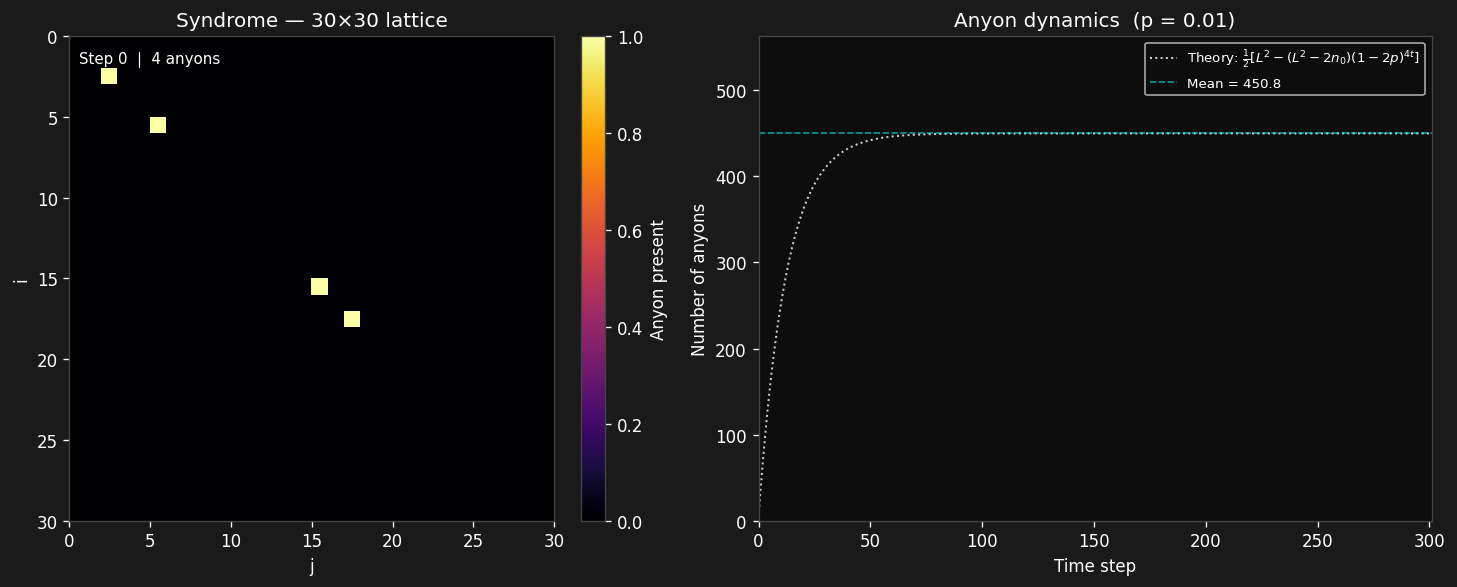

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
fig.patch.set_facecolor('#1a1a1a')

# — Heatmap syndrome —
im = ax1.imshow(anyons_frames[0], vmin=0, vmax=1,
                cmap='inferno', interpolation='nearest',
                extent=[0, L, L, 0])
cbar = fig.colorbar(im, ax=ax1, fraction=0.046, pad=0.04)
cbar.set_label("Anyon present", color='white')
cbar.ax.yaxis.set_tick_params(color='white')
plt.setp(cbar.ax.yaxis.get_ticklabels(), color='white')
ax1.set_title(f"Syndrome — {L}×{L} lattice", fontsize=12)
ax1.set_xlabel("j"); ax1.set_ylabel("i")
step_text = ax1.text(0.02, 0.97, '', transform=ax1.transAxes,
                     color='white', fontsize=9, va='top')

# — Courbe énergie —
ax2.set_facecolor('#0d0d0d')
ax2.set_xlim(0, n_steps + 1)
ax2.set_ylim(0, max(energies) * 1.15 + 2)
ax2.set_xlabel("Time step")
ax2.set_ylabel("Number of anyons")
ax2.set_title(f"Anyon dynamics  (p = {p})", fontsize=12)
t_axis = np.arange(n_steps + 1)
n_theory = 0.5 * (L**2 - (L**2 - 2 * energies[0]) * (1 - 2 * p) ** (4 * t_axis))
ax2.plot(t_axis, n_theory, color='white', lw=1.2, linestyle=':', alpha=0.8,
         label=r'Theory: $\frac{1}{2}[L^2-(L^2-2n_0)(1-2p)^{4t}]$')
ax2.axhline(np.mean(energies[50:]), color='cyan', lw=1,
            linestyle='--', alpha=0.6, label=f'Mean = {np.mean(energies[50:]):.1f}')
ax2.legend(fontsize=8)
line, = ax2.plot([], [], color='#ff6b35', lw=1.5)

def update(frame):
    im.set_array(anyons_frames[frame])
    step_text.set_text(f'Step {frame}  |  {energies[frame]} anyons')
    line.set_data(range(frame + 1), energies[:frame + 1])
    return im, line, step_text

ani = FuncAnimation(fig, update, frames=len(anyons_frames),
                    interval=40, blit=True)
plt.tight_layout()
plt.show()
# ani.save('toric_code.gif', writer='pillow', fps=25)  # décommenter pour sauvegarder

## 3. Anyon density vs $p$ — *Densité d'anyons vs $p$*

We measure the **anyon density** $\langle n_{\text{anyons}} \rangle / L^2$ after equilibration, as a function of $p$, for several sizes $L$.

**Expected result.** Since the model has no decoder, the density converges to $1/2$ for every $p$: after $n_{\text{eq}} = 100$ steps, $(1-2p)^{4 n_{\text{eq}}} \le 3 \times 10^{-4}$ even for $p = 0.01$. The curve is therefore **nearly flat**, with no transition near $p_{\text{threshold}} \approx 0.103$.

The threshold $p_{\text{threshold}} \approx 0.103$ (Dennis et al., 2002, [2] in the report) is a literature result, drawn as a dashed line **for reference only**. Recovering it would require measuring the *logical* error rate after MWPM decoding (see "Summary").

---

*Version française*

On mesure la **densité d'anyons** $\langle n_{\text{anyons}} \rangle / L^2$ après équilibration, en fonction de $p$, pour plusieurs tailles $L$.

**Résultat attendu.** Comme le modèle n'a pas de décodeur, la densité converge vers $1/2$ pour tout $p$ : après $n_{\text{eq}} = 100$ pas, $(1-2p)^{4 n_{\text{eq}}} \le 3 \times 10^{-4}$ même pour $p = 0.01$. La courbe est donc **quasi plate**, et ne présente pas de transition au voisinage de $p_{\text{seuil}} \approx 0.103$.

Le seuil $p_{\text{seuil}} \approx 0.103$ (Dennis et al., 2002 [2] dans le rapport) est un résultat de la littérature, tracé en pointillés **à titre de repère uniquement**. Pour le retrouver, il faudrait mesurer le taux d'erreur *logique* après décodage MWPM (voir « Bilan »).

In [7]:
# Paramètres du scan (réduits pour la rapidité — augmenter pour la précision)
p_values = np.linspace(0.01, 0.25, 25)
L_values = [10, 20, 30]
n_eq   = 100   # pas d'équilibration (ignorés)
n_meas = 200   # pas de mesure

results = {}  # {L: densités moyennes}

for Ls in L_values:
    print(f"L = {Ls}...", end=' ', flush=True)
    dens = []
    for pv in p_values:
        syn = np.ones((Ls, Ls), dtype=np.int8)
        # équilibration
        for _ in range(n_eq):
            syn = step(syn, pv, Ls)
        # mesure
        counts = []
        for _ in range(n_meas):
            syn = step(syn, pv, Ls)
            counts.append(n_anyons(syn) / Ls**2)
        dens.append(np.mean(counts))
    results[Ls] = dens
    print("✓")

print("Scan finished.")


L = 10... ✓
L = 20... ✓
L = 30... ✓
Scan finished.


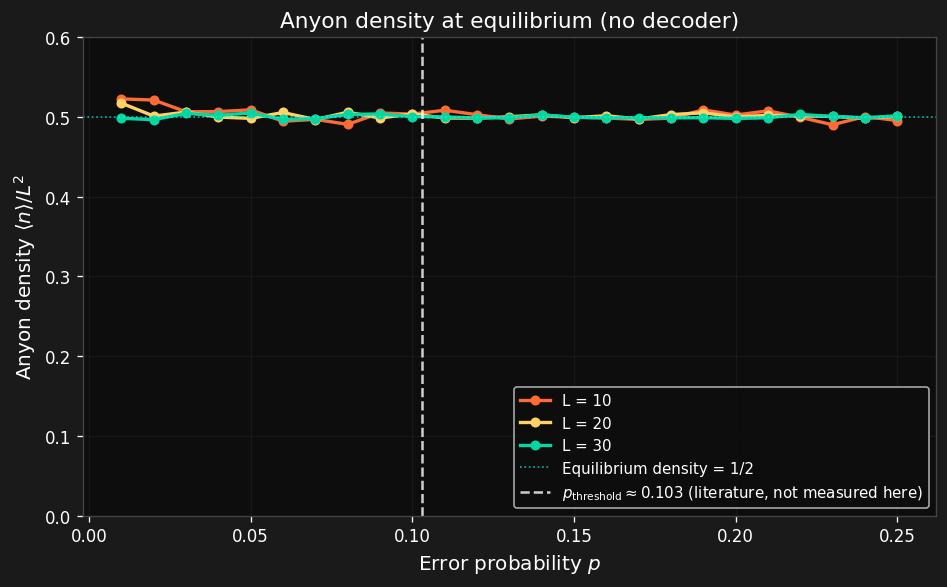

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
fig.patch.set_facecolor('#1a1a1a')
ax.set_facecolor('#0d0d0d')

colors = ['#ff6b35', '#ffd166', '#06d6a0']
for (Ls, col) in zip(L_values, colors):
    ax.plot(p_values, results[Ls], 'o-', color=col,
            lw=2, ms=5, label=f'L = {Ls}')

ax.axhline(0.5, color='cyan', lw=1, linestyle=':', alpha=0.7,
           label='Equilibrium density = 1/2')
ax.axvline(0.103, color='white', lw=1.5, linestyle='--', alpha=0.8,
           label=r'$p_{\mathrm{threshold}} \approx 0.103$ (literature, not measured here)')

ax.set_ylim(0, 0.6)
ax.set_xlabel("Error probability $p$", fontsize=12)
ax.set_ylabel(r"Anyon density $\langle n \rangle / L^2$", fontsize=12)
ax.set_title("Anyon density at equilibrium (no decoder)", fontsize=13)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Comparison of three values of $p$ — *Comparaison de trois valeurs de $p$*

Syndrome snapshots after equilibration ($n_{\text{eq}} = 500$ steps) for three values of $p$:

| $p$ | Reference | Expected observation |
|---|---|---|
| $0.01$ | $p \ll p_{\text{threshold}}$ | Random syndrome, density $\approx 50\%$ |
| $0.103$ | $p \approx p_{\text{threshold}}$ (literature) | Random syndrome, density $\approx 50\%$ |
| $0.20$ | $p > p_{\text{threshold}}$ | Random syndrome, density $\approx 50\%$ |

The three images are statistically indistinguishable: without a decoder, noise alone is enough to randomize the syndrome. This illustrates why error correction (section 11 of the report) is necessary.

---

*Version française*

Snapshots du syndrome après équilibration ($n_{\text{eq}} = 500$ pas) pour trois valeurs de $p$ :

| $p$ | Repère | Observation attendue |
|---|---|---|
| $0.01$ | $p \ll p_{\text{seuil}}$ | Syndrome aléatoire, densité $\approx 50\%$ |
| $0.103$ | $p \approx p_{\text{seuil}}$ (littérature) | Syndrome aléatoire, densité $\approx 50\%$ |
| $0.20$ | $p > p_{\text{seuil}}$ | Syndrome aléatoire, densité $\approx 50\%$ |

Les trois images sont statistiquement indiscernables : sans décodeur, le bruit seul suffit à randomiser le syndrome. Ce constat illustre pourquoi la correction d'erreur (section 11 du rapport) est nécessaire.

In [ ]:
L_snap = 40
p_snap = [0.01, 0.103, 0.20]
labels = ['$p=0.01$',
          '$p=0.103$ ($\\approx p_{\\mathrm{threshold}}$)',
          '$p=0.20$']
n_eq_snap = 500

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor('#1a1a1a')
fig.suptitle(f"Syndrome after equilibration — {L_snap}×{L_snap} lattice",
             color='white', fontsize=13)

for ax, pv, lab in zip(axes, p_snap, labels):
    syn = np.ones((L_snap, L_snap), dtype=np.int8)
    for _ in range(n_eq_snap):
        syn = step(syn, pv, L_snap)
    snap = (1 - syn) / 2
    ax.imshow(snap, vmin=0, vmax=1, cmap='inferno',
              interpolation='nearest')
    ax.set_title(lab, fontsize=10, pad=6)
    ax.set_xticks([]); ax.set_yticks([])
    n = n_anyons(syn)
    ax.set_xlabel(f"{n} anyons  ({100*n/L_snap**2:.1f}%)", color='white')

plt.tight_layout()
plt.show()

## Summary

| What the simulation shows | Link with the report |
|---|---|
| An $X_e$ error flips exactly two adjacent plaquettes | Prop. 9.1 and 10.1 |
| Anyons always come in even number (checked numerically) | Proposition 9.2 |
| Without correction, the anyon density follows $\tfrac12[1-(1-2p)^{4t}]$ and converges to $1/2$ for every $p$ | Illustrates the need for decoding (section 11) |

**What the simulation does not show:**
- the threshold $p_{\text{threshold}} \approx 0.103$ (Prop. 11.1): it is a literature result, not measured here;
- the distance $d = L$ and the exponential decay of the logical error (Theorem 12.1);
- diffusion in the rigorous quantum sense.

**To reproduce the threshold**, one would need to simulate the full *code capacity model* (Example 13.1 of the report):
1. draw i.i.d. $X$ errors with probability $p$ on the $2L^2$ edges;
2. compute the syndrome;
3. decode with MWPM (for example with [PyMatching](https://github.com/oscarhiggott/PyMatching));
4. check whether the error composed with the correction is a non-contractible cycle (logical error);
5. plot the **logical error rate as a function of $p$** for several $L$: the curves cross at the threshold.

---

*Version française*

## Bilan

| Ce que la simulation montre | Lien avec le rapport |
|---|---|
| Une erreur $X_e$ retourne exactement deux plaquettes adjacentes | Prop. 9.1 et 10.1 |
| Anyons toujours en nombre pair (vérifié numériquement) | Proposition 9.2 |
| Sans correction, la densité d'anyons suit $\tfrac12[1-(1-2p)^{4t}]$ et converge vers $1/2$ pour tout $p$ | Illustre la nécessité du décodage (section 11) |

**Ce que la simulation ne montre pas :**
- le seuil $p_{\text{seuil}} \approx 0.103$ (Prop. 11.1) : c'est un résultat de la littérature, non mesuré ici ;
- la distance $d = L$ et la décroissance exponentielle de l'erreur logique (Théorème 12.1) ;
- la diffusion au sens quantique rigoureux.

**Pour reproduire le seuil**, il faudrait simuler le *code capacity model* complet (Exemple 13.1 du rapport) :
1. tirer une erreur $X$ i.i.d. de probabilité $p$ sur les $2L^2$ arêtes ;
2. calculer le syndrome ;
3. décoder par MWPM (par exemple avec [PyMatching](https://github.com/oscarhiggott/PyMatching)) ;
4. tester si l'erreur composée avec la correction est un cycle non contractible (erreur logique) ;
5. tracer le **taux d'erreur logique en fonction de $p$** pour plusieurs $L$ : les courbes se croisent au seuil.